In [8]:
# Setup & reproducibility


# os : 폴더·파일 경로를 다루는 파이썬 기본 라이브러리
import os
# random : 파이썬 기본 무작위 함수
import random
# numpy : 숫자 배열 계산
import numpy as np
# torch : 파이토치 (딥러닝 프레임워크)
import torch

# SEED : 무작위 결과를 고정할 기준 숫자
SEED = 42

def seed_everything(seed):
    # 파이썬 기본 random 고정
    random.seed(seed)
    # 파이썬 해시값 생성 방식 고정
    os.environ["PYTHONHASHSEED"] = str(seed)
    # numpy 무작위 고정
    np.random.seed(seed)
    # 파이토치 CPU 연산 무작위 고정
    torch.manual_seed(seed)
    # 파이토치 GPU 연산 무작위 고정
    torch.cuda.manual_seed_all(seed)
    # cudnn(GPU 가속 라이브러리)이 매번 같은 계산 방식을 쓰도록 강제
    torch.backends.cudnn.deterministic = True
    # 가장 빠른 계산 방식 자동 탐색 끄기 (켜두면 실행마다 결과가 달라질 수 있음)
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)

# GPU를 쓸 수 있으면 "cuda", 아니면 "cpu"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
# GPU 이름 출력 (T4가 잡혔는지 확인)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# → 모든 무작위 요소를 SEED=42로 고정해 누가 실행해도 같은 결과가 나오게 하고,
#   사용할 장치(GPU/CPU)와 GPU 이름을 확인하겠다

device: cuda
GPU: Tesla T4


In [2]:
# Mount Drive, create folders & unzip data


# os : 폴더·경로를 다루는 기본 라이브러리 (런타임 재시작 후에도 이 셀만으로 실행되도록 다시 불러옴)
import os
# Colab에서 구글 드라이브에 접근하는 도구
from google.colab import drive
# 내 드라이브를 /content/drive 위치에 연결 (처음엔 로그인·권한 허용 창이 뜸)
drive.mount("/content/drive")

# PROJECT_DIR : 드라이브 안 프로젝트 폴더
PROJECT_DIR = "/content/drive/MyDrive/dacon_chest_xray"
# 하위 폴더 3개 생성 / exist_ok=True : 이미 있으면 에러 없이 넘어감
for sub in ["data", "models", "submissions"]:
    os.makedirs(os.path.join(PROJECT_DIR, sub), exist_ok=True)

# ZIP_PATH : 드라이브에 올린 압축파일 위치
ZIP_PATH = os.path.join(PROJECT_DIR, "data", "open.zip")
# DATA_DIR : 압축을 풀 Colab 로컬 위치 (드라이브보다 읽기 속도가 훨씬 빠름)
DATA_DIR = "/content/data"

# 압축파일이 있는지 확인 후 처리
if os.path.exists(ZIP_PATH):
    # -q : 조용히 / -o : 덮어쓰기 / -d : 풀 위치 지정
    !unzip -q -o "{ZIP_PATH}" -d "{DATA_DIR}"
    print("unzip done:", os.listdir(DATA_DIR))
else:
    print("zip not found → 드라이브 data 폴더를 확인하세요")
    print("현재 data 폴더:", os.listdir(os.path.join(PROJECT_DIR, "data")))


# → 드라이브를 연결해 프로젝트 폴더를 만들고,
#   압축파일을 Colab 로컬(/content/data)에 풀어 목록을 확인하겠다

Mounted at /content/drive
unzip done: ['train', 'train.csv', 'test.csv', 'sample_submission.csv', 'test']


train: (5216, 2) / test: (624, 1)
        file_name  label
0  train_0001.png      0
1  train_0002.png      0
2  train_0003.png      0
3  train_0004.png      0
4  train_0005.png      0

[Class count]
label
0    1341
1    3875
Name: count, dtype: int64

[Class ratio %]
label
0    25.7
1    74.3
Name: proportion, dtype: float64

imbalance ratio (pneumonia / normal): 2.89


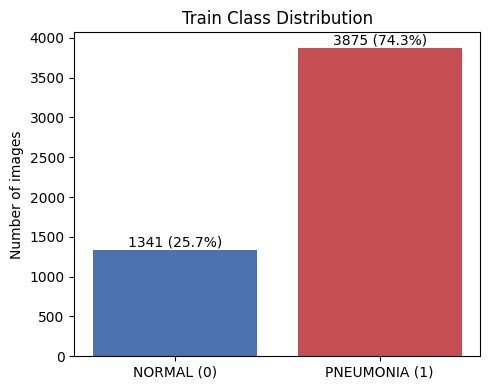

In [3]:
# Class distribution


# pandas : 표 형태 데이터를 다루는 라이브러리
import pandas as pd
# matplotlib : 그래프 그리기
import matplotlib.pyplot as plt

# os.path.join : 경로 이어붙이기 → "/content/data/train.csv"
# pd.read_csv : csv 파일을 표(DataFrame)로 불러오기
train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

# .shape : (행 개수, 열 개수) → 이미지 수가 5216, 624와 맞는지 확인
print("train:", train_df.shape, "/ test:", test_df.shape)
# .head() : 위에서 5줄 미리보기 → 열 이름과 값 형태 확인
print(train_df.head())

# value_counts() : label 값(0, 1)별 개수 세기 / sort_index() : 0, 1 순서로 정렬
counts = train_df["label"].value_counts().sort_index()
# normalize=True : 개수 대신 비율 / * 100 : 퍼센트 / round(1) : 소수 첫째 자리까지
ratio = (train_df["label"].value_counts(normalize=True).sort_index() * 100).round(1)

print("\n[Class count]")
print(counts)
print("\n[Class ratio %]")
print(ratio)
# 폐렴 개수 ÷ 정상 개수 → 불균형 정도를 한 숫자로 표현
# :.2f : 소수 둘째 자리까지 표시
print(f"\nimbalance ratio (pneumonia / normal): {counts[1] / counts[0]:.2f}")

# figsize=(5, 4) : 그림 크기 (가로 5, 세로 4인치)
plt.figure(figsize=(5, 4))
# plt.bar : 막대그래프 / 정상은 파랑, 폐렴은 빨강
plt.bar(["NORMAL (0)", "PNEUMONIA (1)"], counts.values, color=["#4C72B0", "#C44E52"])
# enumerate : 순서 번호(i)와 값을 함께 꺼냄 / zip : 개수와 비율을 짝지어 꺼냄
for i, (c, r) in enumerate(zip(counts.values, ratio.values)):
    # plt.text : 막대 위에 글자 표시 / ha="center" : 가운데 정렬 / va="bottom" : 막대 바로 위에
    plt.text(i, c, f"{c} ({r}%)", ha="center", va="bottom")
plt.title("Train Class Distribution")
plt.ylabel("Number of images")
# 그래프 요소 간격 자동 조정
plt.tight_layout()
plt.show()


# → train.csv와 test.csv를 불러와 개수를 확인하고,
#   정상/폐렴 클래스의 개수·비율·불균형 배율을 계산해 막대그래프로 보여주겠다

### 📊 Mission 1-1. 데이터 구조 및 클래스 분포

**데이터 구성**
| 구분 | 내용 |
|---|---|
| train | 흉부 X-ray 5,216장 (`train.csv`: file_name, label) |
| test | 흉부 X-ray 624장 (`test.csv`: file_name만 존재, 정답 없음) |
| label | 0 = 정상(NORMAL), 1 = 폐렴(PNEUMONIA) |
| 출처 | Kermany et al., Mendeley Data (CC BY 4.0) |

**클래스 분포 (train)**
| 클래스 | 개수 | 비율 |
|---|---|---|
| 정상 (0) | 1,341 | 25.7% |
| 폐렴 (1) | 3,875 | 74.3% |

- 불균형 배율(폐렴/정상): **2.89배** → 불균형 데이터
- 모든 이미지를 "폐렴"으로 예측해도 Accuracy 74.3% → Accuracy는 성능을 과대평가할 위험이 큼

**불균형이 일으킬 수 있는 문제**
- 모델이 다수 클래스(폐렴) 쪽으로 치우쳐 예측하는 경향
- 소수 클래스(정상)를 충분히 학습하지 못해 Specificity가 낮아질 수 있음
- → 주 평가지표로 ROC-AUC, 보조로 Sensitivity / Specificity / F1 사용

**데이터 관찰 사항**
- `head()` 결과 앞쪽 파일이 모두 정상(0) → 파일이 클래스 순으로 정렬되어 있을 가능성
- → 학습/검증 분리 및 DataLoader 구성 시 반드시 셔플 필요

In [4]:
# Label order & image properties


# PIL(Pillow) : 파이썬 이미지 처리 라이브러리 / Image : 이미지를 열고 정보를 읽는 도구
from PIL import Image
# Counter : 리스트 안 값들이 각각 몇 번 나오는지 세주는 도구
from collections import Counter

# 1) 파일 순서와 label의 관계 확인
# .iloc[a:b] : a번째부터 b-1번째 행까지 선택
# 정렬돼 있다면 1341번째(인덱스 1340)까지 0, 그다음부터 1이어야 함
print("[Label order check]")
print(train_df.iloc[1338:1344])
# label 값이 바뀌는 지점이 몇 번 있는지 세기
# .diff() : 바로 위 행과의 차이 (0→1로 바뀌면 1) / .ne(0) : 0이 아닌 것(=바뀐 지점)만 True
change_points = train_df["label"].diff().fillna(0).ne(0).sum()
print("label이 바뀌는 지점 수:", change_points)

# 2) 이미지 크기(가로×세로)와 채널 모드 확인
TRAIN_IMG_DIR = os.path.join(DATA_DIR, "train")

sizes = []
modes = []
# train_df의 파일 이름을 하나씩 꺼냄
for fname in train_df["file_name"]:
    # Image.open : 이미지 열기 (이 시점엔 파일 머리 정보만 읽어서 빠름)
    with Image.open(os.path.join(TRAIN_IMG_DIR, fname)) as img:
        # .size : (가로, 세로) 픽셀 수
        sizes.append(img.size)
        # .mode : 색상 방식 ("L"=흑백 1채널, "RGB"=컬러 3채널 등)
        modes.append(img.mode)

# 가로·세로를 따로 꺼내 표로 만들어 요약 통계 보기
size_df = pd.DataFrame(sizes, columns=["width", "height"])
print("\n[Image size summary]")
# .describe() : 개수·평균·최소·최대 등 요약 통계 / .round(0) : 정수로 반올림
print(size_df.describe().round(0))

print("\n[Image mode count]")
# 각 모드가 몇 장인지 출력
print(Counter(modes))


# → 파일 번호 순서대로 label이 정렬돼 있는지 확인하고,
#   train 이미지 전체의 크기 분포와 채널 모드(흑백/컬러)를 확인하겠다

[Label order check]
           file_name  label
1338  train_1339.png      0
1339  train_1340.png      0
1340  train_1341.png      0
1341  train_1342.png      1
1342  train_1343.png      1
1343  train_1344.png      1
label이 바뀌는 지점 수: 1

[Image size summary]
        width  height
count  5216.0  5216.0
mean    224.0   224.0
std       0.0     0.0
min     224.0   224.0
25%     224.0   224.0
50%     224.0   224.0
75%     224.0   224.0
max     224.0   224.0

[Image mode count]
Counter({'L': 5216})


### 🖼 Mission 1-2. 이미지 속성 확인

| 항목 | 결과 | 의미 / 대응 |
|---|---|---|
| 파일 정렬 | `train_0001~1341` = 정상, `train_1342~5216` = 폐렴 (전환 지점 1회) | 완전 정렬 상태 → 층화 분할 + 셔플 필수 |
| 이미지 크기 | 전체 224×224 (std = 0) | 대회 측 사전 리사이즈 → 별도 리사이즈 불필요, ImageNet 표준 입력 크기와 일치 |
| 채널 | 전체 `L` (흑백 1채널) | ImageNet 사전학습 모델은 3채널 입력 → 흑백 채널을 3번 복제하여 입력 |

**고려 사항**
- 원본 Kermany 데이터는 이미지 크기가 제각각이었으므로, 정사각형 리사이즈 과정에서 가로세로 비율 왜곡이 있었을 가능성
- 파일 번호와 label이 완전히 대응 → 셔플 없이 순서대로 분할·학습하면 심각한 편향 발생

In [5]:
# Sample images (NORMAL vs PNEUMONIA)


# N_SAMPLES : 클래스별로 보여줄 이미지 수
N_SAMPLES = 5

# label이 0인 행만 골라 그중 N_SAMPLES개를 무작위 추출
# .sample(n, random_state) : n개를 무작위로 뽑음 / random_state=SEED : 매번 같은 이미지가 뽑히도록 고정
normal_samples = train_df[train_df["label"] == 0].sample(N_SAMPLES, random_state=SEED)
pneumonia_samples = train_df[train_df["label"] == 1].sample(N_SAMPLES, random_state=SEED)

# plt.subplots(행, 열) : 여러 칸짜리 그림판 생성 → 2행(정상/폐렴) × 5열
# axes : 각 칸을 가리키는 배열 / figsize : 전체 그림 크기
fig, axes = plt.subplots(2, N_SAMPLES, figsize=(3 * N_SAMPLES, 7.5))

# 행 번호(row), 샘플 표, 행 제목을 짝지어 반복
for row, (samples, title) in enumerate([(normal_samples, "NORMAL"),
                                        (pneumonia_samples, "PNEUMONIA")]):
    # 각 행 안에서 이미지 하나씩 꺼냄 / .iterrows() : 표를 한 행씩 꺼냄
    for col, (_, r) in enumerate(samples.iterrows()):
        img = Image.open(os.path.join(TRAIN_IMG_DIR, r["file_name"]))
        ax = axes[row, col]
        # cmap="gray" : 흑백 이미지를 흑백으로 표시 (지정 안 하면 엉뚱한 색으로 나옴)
        ax.imshow(img, cmap="gray")
        # 각 이미지 위에 클래스와 파일 이름 표시
        ax.set_title(f"{title}\n{r['file_name']}", fontsize=10)
        # 축 눈금 숨기기
        ax.axis("off")

plt.suptitle("Sample Chest X-rays (Top: NORMAL / Bottom: PNEUMONIA)", fontsize=14)
plt.tight_layout()
plt.show()


# → 정상과 폐렴 이미지를 클래스별로 5장씩 무작위로 뽑아
#   위아래로 나란히 보여주어 두 클래스의 시각적 차이를 비교하겠다

[X-ray 이미지 출력 제거 — 대회 데이터 재배포 금지. 해석은 04_Report/Final_Report.md 참고]


### 👀 Mission 1-3. 샘플 이미지 관찰

> 클래스별 무작위 5장씩(총 10장, `random_state=42`)을 육안으로 비교함

#### 1. 폐 영역의 밝기 차이
- **정상**: 폐 안쪽이 검고 깨끗함. 갈비뼈 사이가 선명하고 심장 경계도 또렷함
- **폐렴**: `train_5160`은 폐 전체가 뿌옇고 하얗게 덮여 있음. `train_3842`는 폐 곳곳에 얼룩덜룩한 음영(침윤)이 보임
  - X-ray에서 공기는 검게, 염증·액체는 하얗게 나타남 → 공기가 차 있어야 할 폐포에 염증이 생겨 하얗게 보이는 것
- **구분이 어려운 사례**: `train_3582`, `train_3631`은 폐렴이지만 정상과 육안 구분이 어려울 정도로 비슷함
  - → 모델이 헷갈릴 가능성이 높은 사례로, **Mission 4 오답 분석 시 확인 대상**

#### 2. `R` 표식
- 대부분의 이미지에 `R`(Right, 환자의 오른쪽) 표식이 있으며, 위치와 크기가 이미지마다 다름
- 정상·폐렴 양쪽에 모두 존재하므로 현재로서는 큰 문제로 보이지 않음
- → 다만 모델이 표식을 근거로 판단하지 않는지 **Mission 5 Grad-CAM에서 반드시 확인**

#### 3. 검은 여백과 기울어짐 ⚠️
- 폐렴 샘플에서 검은 띠(여백)가 눈에 띔
  - `train_5089`: 이미지가 기울어져 모서리가 검게 비어 있음
  - `train_3582`, `train_3631`: 위아래에 큰 검은 영역이 있음
- 정상 샘플은 대부분 화면을 꽉 채우고 있음
- 샘플 5장씩만 관찰했으므로 단정할 수 없으나, **"검은 여백이 많으면 폐렴"이라는 패턴이 데이터 전체에 존재한다면** 모델이 폐가 아닌 여백을 보고 맞히는 **지름길 학습(Shortcut Learning)** 위험이 있음
  - Grad-CAM 원 논문(Selvaraju et al., 6.3절)의 '의사/간호사 분류 모델이 복장 대신 얼굴·머리 모양을 근거로 판단한 사례'와 같은 구조
- → Grad-CAM으로 모델이 여백 영역에 주목하는지 검증 필요

#### 4. 비율 처리 방식
- 정사각형으로 맞추는 과정에서 이미지가 찌그러졌다기보다는, **원래 비율을 유지한 채 검은 여백을 덧대(padding) 224×224로 맞춘 이미지**가 섞여 있는 것으로 보임
- → 3번의 검은 여백이 생긴 원인일 가능성

#### 5. 소아 데이터 특징
- `train_5160`처럼 팔을 들고 촬영한 사진, 몸이 작아 이미지 내 차지 비율이 다른 사진 등 촬영 자세가 일정하지 않음
- 원본이 소아(1~5세) 흉부 X-ray 데이터이기 때문으로 보임
- → 밝기·대비·자세의 다양성은 **데이터 증강(밝기·대비 조절, 소폭 회전) 적용의 근거**가 됨

#### 📌 정리 및 후속 계획
| 관찰 | 후속 조치 | 관련 미션 |
|---|---|---|
| 육안 구분이 어려운 폐렴 사례 존재 | 오답 사례에 포함되는지 확인 | Mission 4 |
| `R` 표식, 검은 여백·기울어짐 | Grad-CAM으로 모델 주목 영역 검증 | Mission 5 |
| 촬영 조건·자세 다양성 | 데이터 증강 전략 후보 | Mission 2 |

**한계**: 샘플 10장 관찰 결과이므로, 여백 패턴이 클래스와 실제로 관련 있는지는 추가 확인 필요

[Black pixel ratio by class]
        count   mean    std    min    25%    50%    75%    max
label                                                         
0      1341.0  0.247  0.091  0.008  0.184  0.245  0.312  0.508
1      3875.0  0.356  0.107  0.000  0.289  0.358  0.425  0.716

[Images with padding > 5% (%)]
label
0    99.1
1    99.6
Name: has_padding, dtype: float64


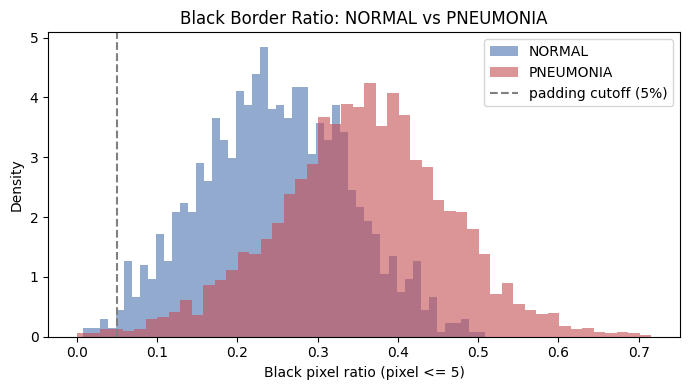

In [6]:
# Black border (padding) ratio by class


# BLACK_THRESHOLD : 이 값 이하 밝기를 "인위적인 검은 여백"으로 간주 (0=완전 검정, 255=흰색)
BLACK_THRESHOLD = 5
# PAD_CUTOFF : 검은 픽셀이 이미지의 5% 넘으면 "여백 있는 이미지"로 분류
PAD_CUTOFF = 0.05

black_ratios = []
for fname in train_df["file_name"]:
    # np.array(Image.open(...)) : 이미지를 (224, 224) 숫자 배열로 변환 (각 칸 = 픽셀 밝기 0~255)
    arr = np.array(Image.open(os.path.join(TRAIN_IMG_DIR, fname)))
    # arr <= 5 : 각 픽셀이 기준 이하면 True / .mean() : True 비율 = 검은 픽셀 비율
    black_ratios.append((arr <= BLACK_THRESHOLD).mean())

# 계산한 비율을 train_df에 새 열로 추가
train_df["black_ratio"] = black_ratios
# 여백 있는 이미지 여부 (True/False)
train_df["has_padding"] = train_df["black_ratio"] > PAD_CUTOFF

# 1) 클래스별 검은 픽셀 비율 요약
# .groupby("label") : label(0/1)별로 묶음 / .describe() : 평균·중앙값 등 요약 통계
print("[Black pixel ratio by class]")
print(train_df.groupby("label")["black_ratio"].describe().round(3))

# 2) 클래스별 "여백 있는 이미지" 비율
# has_padding의 평균 = True 비율 / * 100 : 퍼센트
pad_rate = (train_df.groupby("label")["has_padding"].mean() * 100).round(1)
print("\n[Images with padding > 5% (%)]")
print(pad_rate)

# 3) 분포 시각화 (히스토그램)
plt.figure(figsize=(7, 4))
for label, name, color in [(0, "NORMAL", "#4C72B0"), (1, "PNEUMONIA", "#C44E52")]:
    # bins=50 : 구간 50개 / alpha=0.6 : 반투명 (두 분포가 겹쳐 보이도록)
    # density=True : 개수 대신 비율로 그림 (두 클래스 개수가 달라도 모양 비교 가능)
    plt.hist(train_df.loc[train_df["label"] == label, "black_ratio"],
             bins=50, alpha=0.6, density=True, label=name, color=color)
# axvline : 세로 기준선 / 여백 판정 기준(5%) 표시
plt.axvline(PAD_CUTOFF, color="gray", linestyle="--", label="padding cutoff (5%)")
plt.xlabel("Black pixel ratio (pixel <= 5)")
plt.ylabel("Density")
plt.title("Black Border Ratio: NORMAL vs PNEUMONIA")
plt.legend()
plt.tight_layout()
plt.show()


# → 이미지마다 거의 완전한 검정 픽셀(밝기 5 이하)의 비율을 계산해
#   정상과 폐렴 사이에 검은 여백 차이가 있는지 숫자와 그래프로 비교하겠다

### 🔍 Mission 1-4. 검은 영역 비율 검증 (1차)

**가설**: 샘플 관찰에서 폐렴 이미지에 검은 여백이 더 많아 보였음 → 데이터 전체에서도 그런가?

**방법**: 이미지별로 밝기 5 이하(0~255 중) 픽셀의 비율을 계산하여 클래스별 비교

**결과**
| 클래스 | 평균 | 중앙값 | 여백 5% 초과 이미지 |
|---|---|---|---|
| 정상 | 24.7% | 24.5% | 99.1% |
| 폐렴 | 35.6% | 35.8% | 99.6% |

**해석**
- 거의 모든 이미지가 기준(5%)을 넘음 → 이 지표는 패딩뿐 아니라 **몸 바깥 공기(배경)**까지 함께 측정하고 있었음
  - 가정("완전 검정 = 패딩")이 틀렸음 → 측정 방식의 한계
- 그럼에도 폐렴 이미지의 검은 면적이 평균 약 11%p 더 넓고, 분포가 뚜렷하게 오른쪽으로 이동함
- → 원인(패딩·체격·촬영 조건)과 무관하게, **폐렴과 직접 관계없는 "검은 면적"이 클래스별로 다름** → 지름길 학습의 재료가 실제로 존재

**배운 점**
- X-ray에서는 패딩과 몸 바깥 공기가 모두 거의 완전한 검정으로 나타나므로, 단순 픽셀 밝기로는 둘을 구분할 수 없음
- → 2차 검증: "줄 전체가 검은 행·열"만 패딩으로 보는 방식으로 재측정

#### 💡 해석: 측정은 섞였지만 분포 차이는 확실함

**클래스 간 차이**
- 정상 평균 **24.7%** vs 폐렴 평균 **35.6%** (중앙값도 24.5% vs 35.8%)
- 히스토그램에서 폐렴 분포가 오른쪽으로 뚜렷하게 이동해 있음
- 측정값에는 패딩·몸 바깥 배경·어두운 폐 영역이 섞여 있어 "정확히 무엇이 검은지"는 구분되지 않음

**의미: 지름길 학습의 재료가 실제로 존재함**
- 원인이 무엇이든, **"이미지 안의 검은 면적"이라는 폐렴 자체와 무관한 특징이 클래스에 따라 다름**
- 모델 입장에서는 폐를 자세히 보지 않고 **"전체적으로 검은 면적이 넓으면 폐렴"**이라고 판단해도 어느 정도 맞힐 수 있음
- → 높은 성능이 나오더라도 그 근거가 폐 병변인지 반드시 검증해야 함 (Grad-CAM)

**가능한 원인 (현재 데이터로는 단정 불가)**
1. 폐렴 이미지에 패딩·기울어짐이 더 많다
2. 폐렴 환아가 더 어려서 몸이 작고, 그만큼 배경이 넓다
3. 두 클래스의 촬영 장비·설정이 달랐다

**후속 계획**
- 1번 원인 확인 → 2차 검증(줄 전체가 검은 행·열만 패딩으로 측정)
- 2·3번은 환자 정보·촬영 정보가 없어 데이터로 확인 불가 → 보고서 한계로 기록
- Mission 5 Grad-CAM에서 모델이 폐 바깥(배경·여백) 영역에 주목하는지 중점 확인

[Padding ratio by class]
        count   mean    std  min    25%    50%    75%    max
label                                                       
0      1341.0  0.176  0.086  0.0  0.114  0.177  0.232  0.419
1      3875.0  0.315  0.105  0.0  0.248  0.319  0.384  0.711

[Images with any padding line (%)]
label
0    99.3
1    99.8
Name: has_pad_line, dtype: float64


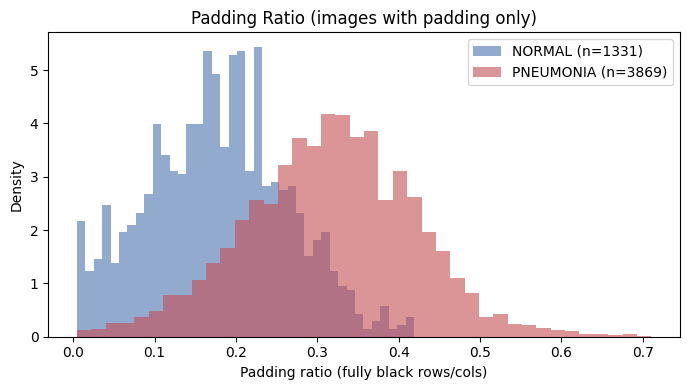

In [7]:
# Padding ratio (fully black rows/columns)


pad_ratios = []
for fname in train_df["file_name"]:
    arr = np.array(Image.open(os.path.join(TRAIN_IMG_DIR, fname)))
    # arr.max(axis=1) : 가로줄(행)마다 가장 밝은 픽셀값 → 그 값도 5 이하면 줄 전체가 검은 것
    black_rows = (arr.max(axis=1) <= BLACK_THRESHOLD).sum()
    # arr.max(axis=0) : 세로줄(열)마다 가장 밝은 픽셀값
    black_cols = (arr.max(axis=0) <= BLACK_THRESHOLD).sum()
    # 검은 줄을 제외한 "실제 내용 영역" 넓이 비율을 구하고, 1에서 빼서 패딩 비율로 계산
    h, w = arr.shape
    content_area = (h - black_rows) * (w - black_cols)
    pad_ratios.append(1 - content_area / (h * w))

train_df["pad_ratio"] = pad_ratios
# 패딩 줄이 조금이라도 있는 이미지 여부
train_df["has_pad_line"] = train_df["pad_ratio"] > 0

# 1) 클래스별 패딩 비율 요약
print("[Padding ratio by class]")
print(train_df.groupby("label")["pad_ratio"].describe().round(3))

# 2) 클래스별 "패딩 줄이 있는 이미지" 비율
print("\n[Images with any padding line (%)]")
print((train_df.groupby("label")["has_pad_line"].mean() * 100).round(1))

# 3) 패딩이 있는 이미지만 골라 분포 비교 (0이 대부분이면 그래프가 안 보이므로)
plt.figure(figsize=(7, 4))
for label, name, color in [(0, "NORMAL", "#4C72B0"), (1, "PNEUMONIA", "#C44E52")]:
    vals = train_df.loc[(train_df["label"] == label) & train_df["has_pad_line"], "pad_ratio"]
    plt.hist(vals, bins=40, alpha=0.6, density=True, label=f"{name} (n={len(vals)})", color=color)
plt.xlabel("Padding ratio (fully black rows/cols)")
plt.ylabel("Density")
plt.title("Padding Ratio (images with padding only)")
plt.legend()
plt.tight_layout()
plt.show()


# → 가로·세로 줄 전체가 검은 부분만 패딩으로 보고 그 면적 비율을 계산해,
#   몸 바깥 배경과 구분된 "진짜 여백"이 클래스별로 다른지 비교하겠다

### 🔍 Mission 1-5. 검은 영역 비율 검증 (2차)

**방법**: 가로줄·세로줄 전체가 검은(최대 밝기 5 이하) 행·열을 패딩으로 보고, 실제 내용 영역 바깥의 면적 비율을 계산

**결과**
| 클래스 | 평균 | 중앙값 | 검은 줄이 있는 이미지 |
|---|---|---|---|
| 정상 | 17.6% | 17.7% | 99.3% |
| 폐렴 | 31.5% | 31.9% | 99.8% |

**해석**
- 거의 모든 이미지에 검은 줄이 존재 → 소아는 체구가 작아 몸 바깥 공기만 지나는 행·열이 생기므로, 이 지표 역시 패딩과 배경을 완전히 분리하지 못함
- 대신 이 지표는 **"실제 내용(몸)이 차지하는 사각형 바깥의 면적"**을 의미함
- 1차(11%p)보다 차이가 더 커짐(14%p) → **폐렴 이미지는 몸이 화면에서 차지하는 비율이 일관되게 작음**
- 원인(패딩·체격·촬영 방식)은 환자·촬영 정보가 없어 확인 불가 → 한계로 기록

**결론 및 후속 계획**
- 두 차례 측정 모두 같은 방향의 차이 → 폐렴과 무관한 "화면 내 몸 크기·여백"이 클래스와 연관됨 (지름길 학습 위험)
- **개선 전략 후보 (Mission 2)**: 내용 영역만 잘라낸 뒤(Crop) 224×224로 재조정 → 여백 차이 제거
  - Baseline vs Crop 적용 모델의 성능과 Grad-CAM 주목 영역을 비교하여 효과 검증
- 측정은 여기서 마무리하고 Baseline 구축으로 진행